# Reconnaissance de chiffres manuscrits : réseau dense ou réseau convolutif ?

**Franck Nankeng** · Projet de deep learning · Python, TensorFlow / Keras

> *English summary — A fully connected network (ANN) and a convolutional network (CNN) are trained on the same
> 1,797 handwritten digits with the same split and early stopping. Beyond test accuracy, I stress-test both models
> on images shifted by one pixel: the experiment shows why convolution matters for vision tasks.*

**La question.** Deux architectures obtiennent souvent des scores proches sur des images bien centrées.
Ce qui les distingue en production, c'est leur comportement quand les images ne ressemblent plus exactement
à celles de l'entraînement. Je compare donc leur exactitude, leur taille, puis leur **robustesse à un décalage d'un pixel**.

*Exercice construit à partir d'un cas vu en formation (cours d'IA du Pr M. Youssfi), que j'ai restructuré
(protocole identique pour les deux réseaux, arrêt précoce, test de robustesse, analyse des erreurs).*

In [1]:
import os, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()
NAVY, SAFFRON, GREY, TEAL = "#14213D", "#E8962E", "#8A93A6", "#2F7F7A"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Données et découpage

In [2]:
digits = load_digits()
X = (digits.images / 16.0).astype("float32")[..., np.newaxis]   # pixels ramenés sur [0, 1], format (8, 8, 1)
y = digits.target

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
print(f"entraînement {len(X_train)} · validation {len(X_val)} · test {len(X_test)} images")

entraînement 1077 · validation 360 · test 360 images


## 2. Deux architectures, un même protocole

In [3]:
def reseau_dense():
    return keras.Sequential([
        keras.Input(shape=(8, 8, 1)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="ANN")

def reseau_convolutif():
    return keras.Sequential([
        keras.Input(shape=(8, 8, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ], name="CNN")

def reseau_convolutif_augmente():
    # Même CNN, précédé de décalages aléatoires appliqués uniquement pendant l'entraînement.
    base = reseau_convolutif()
    return keras.Sequential([keras.Input(shape=(8, 8, 1)),
                             layers.RandomTranslation(0.15, 0.15, fill_mode="constant", fill_value=0.0, seed=SEED),
                             *base.layers], name="CNN_augmente")

LIBELLES = {"ANN": "Réseau dense", "CNN": "CNN", "CNN_augmente": "CNN + augmentation"}

def entrainer(modele):
    modele.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
    hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200,
                      batch_size=32, callbacks=[arret], verbose=0)
    return modele, hist

modeles, historiques = {}, {}
for construire in (reseau_dense, reseau_convolutif, reseau_convolutif_augmente):
    m, h = entrainer(construire())
    modeles[m.name], historiques[m.name] = m, h
    n = f"{m.count_params():,}".replace(",", " ")
    print(f"{LIBELLES[m.name]} : {n} paramètres, arrêt après {len(h.history['loss'])} époques")

Réseau dense : 17 226 paramètres, arrêt après 72 époques


CNN : 35 914 paramètres, arrêt après 62 époques


CNN + augmentation : 35 914 paramètres, arrêt après 91 époques


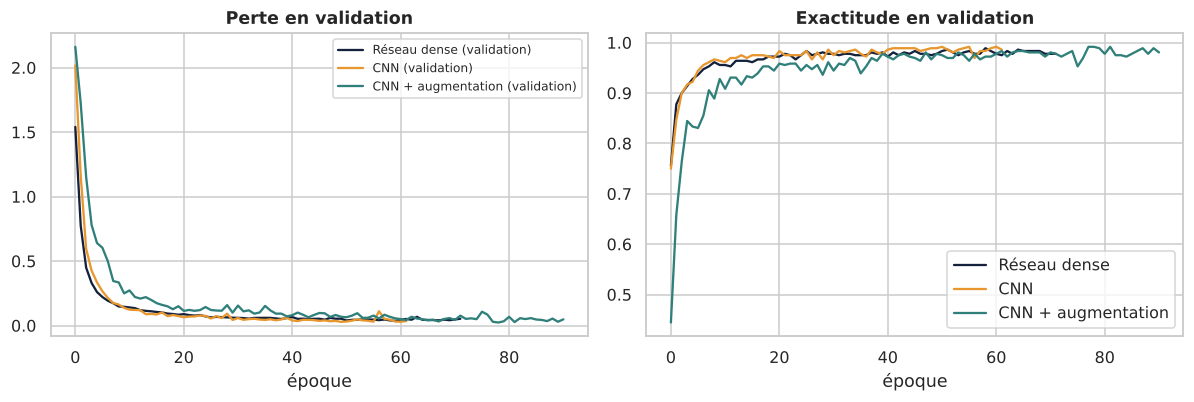

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for nom, couleur in [("ANN", NAVY), ("CNN", SAFFRON), ("CNN_augmente", TEAL)]:
    h = historiques[nom].history
    axes[0].plot(h["val_loss"], color=couleur, label=f"{LIBELLES[nom]} (validation)")
    axes[1].plot(h["val_accuracy"], color=couleur, label=LIBELLES[nom])
axes[0].set_title("Perte en validation"); axes[0].set_xlabel("époque"); axes[0].legend(fontsize=8)
axes[1].set_title("Exactitude en validation"); axes[1].set_xlabel("époque"); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Résultats sur le jeu de test

In [5]:
def decaler(images, dx=0, dy=0):
    # Décale chaque image de dx pixels horizontalement et dy verticalement, en complétant par du blanc.
    out = np.roll(images, shift=(dy, dx), axis=(1, 2))
    if dx > 0: out[:, :, :dx] = 0
    if dx < 0: out[:, :, dx:] = 0
    if dy > 0: out[:, :dy, :] = 0
    if dy < 0: out[:, dy:, :] = 0
    return out

decalages = {"aucun": (0, 0), "1 px à droite": (1, 0), "1 px à gauche": (-1, 0),
             "1 px en bas": (0, 1), "1 px en haut": (0, -1)}
lignes = []
for nom, m in modeles.items():
    ligne = {"modèle": LIBELLES[nom], "paramètres": m.count_params()}
    for lib, (dx, dy) in decalages.items():
        ligne[lib] = m.evaluate(decaler(X_test, dx, dy), y_test, verbose=0)[1]
    lignes.append(ligne)
robustesse = pd.DataFrame(lignes).set_index("modèle")
robustesse["moyenne décalée"] = robustesse[list(decalages)[1:]].mean(axis=1)
robustesse.style.format({c: "{:.1%}" for c in robustesse.columns if c != "paramètres"}
                       | {"paramètres": lambda v: f"{v:,}".replace(",", " ")})

,paramètres,aucun,1 px à droite,1 px à gauche,1 px en bas,1 px en haut,moyenne décalée
modèle,,,,,,,
Réseau dense,17 226,98.9%,52.2%,50.0%,47.5%,43.9%,48.4%
CNN,35 914,98.3%,77.2%,78.3%,65.8%,61.7%,70.8%
CNN + augmentation,35 914,99.2%,98.6%,97.5%,98.6%,97.5%,98.1%


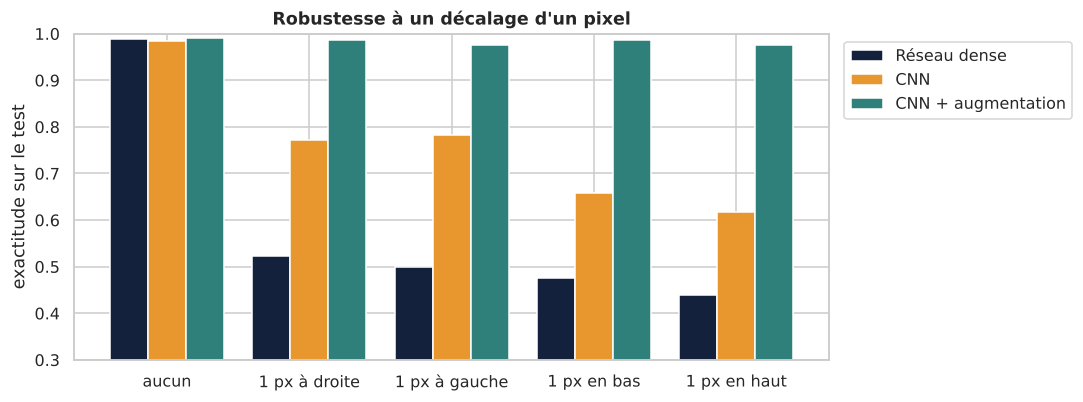

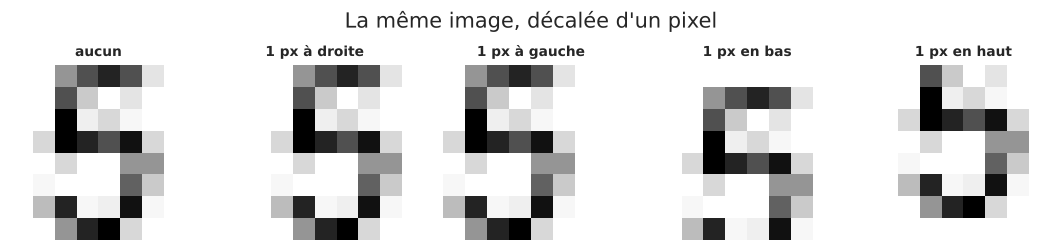

In [6]:
ax = robustesse[list(decalages)].T.plot.bar(figsize=(10, 3.8), color=[NAVY, SAFFRON, TEAL], rot=0, width=0.8)
ax.set_ylim(0.3, 1.0); ax.set_ylabel("exactitude sur le test")
ax.set_title("Robustesse à un décalage d'un pixel")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(10, 2.3))
for ax, (lib, (dx, dy)) in zip(axes, decalages.items()):
    ax.imshow(decaler(X_test[:1], dx, dy)[0, :, :, 0], cmap="Greys"); ax.set_title(lib, fontsize=9); ax.axis("off")
plt.suptitle("La même image, décalée d'un pixel"); plt.tight_layout(); plt.show()

## 4. Où le modèle retenu se trompe-t-il encore ?

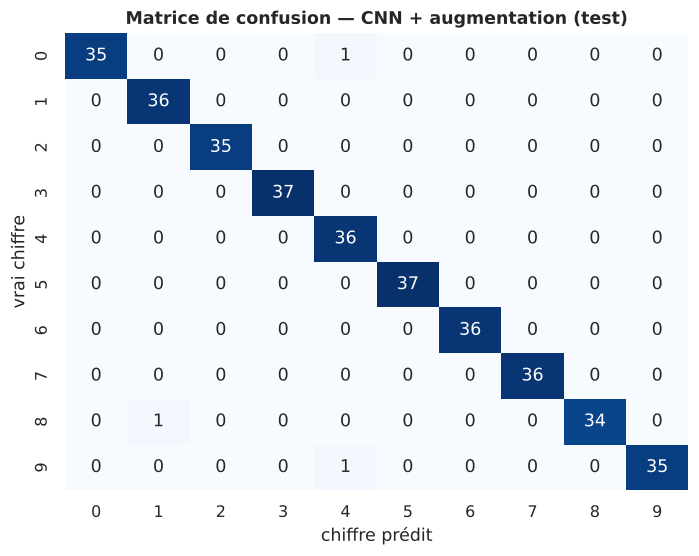

3 erreurs sur 360 images


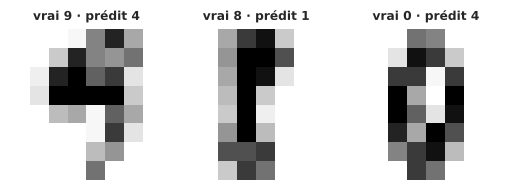

In [7]:
cnn = modeles["CNN_augmente"]
pred = cnn.predict(X_test, verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("chiffre prédit"); ax.set_ylabel("vrai chiffre"); ax.set_title("Matrice de confusion — CNN + augmentation (test)")
plt.tight_layout(); plt.show()

erreurs = np.where(pred != y_test)[0]
print(f"{len(erreurs)} erreurs sur {len(y_test)} images")
if len(erreurs):
    fig, axes = plt.subplots(1, min(len(erreurs), 8), figsize=(1.6 * min(len(erreurs), 8), 2.2), squeeze=False)
    for ax, i in zip(axes[0], erreurs[:8]):
        ax.imshow(X_test[i, :, :, 0], cmap="Greys"); ax.axis("off")
        ax.set_title(f"vrai {y_test[i]} · prédit {pred[i]}", fontsize=8)
    plt.tight_layout(); plt.show()

## 5. Sauvegarder et recharger le modèle

In [8]:
os.makedirs("../models", exist_ok=True)
chemin = "../models/cnn_chiffres.keras"
cnn.save(chemin)
recharge = keras.models.load_model(chemin)
identiques = np.array_equal(recharge.predict(X_test, verbose=0).argmax(axis=1), pred)
print(f"Modèle sauvegardé ({os.path.getsize(chemin) / 1024:.0f} Ko) et rechargé : prédictions identiques = {identiques}")

Modèle sauvegardé (462 Ko) et rechargé : prédictions identiques = True


## Conclusions

**Résultats**
- Sur des images centrées comme à l'entraînement, les trois réseaux se valent : **98,9 %** pour le réseau dense,
  **98,3 %** pour le CNN et **99,2 %** pour le CNN avec augmentation. L'exactitude seule ne permet pas de les départager.
- Décalées d'un seul pixel, les mêmes images font chuter le réseau dense à **48,4 %** en moyenne : il a appris des positions
  de pixels, pas des formes.
- Le CNN résiste mieux (**70,8 %**) grâce à ses filtres partagés et au pooling, mais perd encore 27 points :
  sur une image de 8 × 8, un pixel représente 12,5 % de la largeur.
- En ajoutant des décalages aléatoires pendant l'entraînement, le même CNN conserve **98,1 %** sur les images décalées,
  sans perte sur les images centrées et sans paramètre supplémentaire. Il ne commet que 3 erreurs sur 360 images de test.

**Ce que je retiens.** Avant de déployer un modèle de vision, je le teste sur des données légèrement différentes de celles
de l'entraînement. Le choix de l'architecture compte, mais la façon de préparer les données d'entraînement compte autant.

**Limites et suites.** Des images de 8 × 8 restent très simples. L'étape suivante serait d'appliquer le même protocole
à des images plus grandes (MNIST en 28 × 28, ou des photos réelles), en ajoutant rotations et bruit au test de robustesse.